# Walmart Store Sales Forecasting 

## Project Overview

### Objective

Forecast **weekly sales** for Walmart stores and departments using historical sales patterns, economic indicators, promotions (markdowns), and holiday effects.

### Business Value

Accurate demand forecasting helps improve:

* inventory allocation
* staffing plans
* promotional planning
* supply chain optimization

#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBRegressor

import plotly.express as px
import plotly.graph_objects as go

#### Load Data

In [2]:
train = pd.read_csv("C:\\Users\\User\Documents\\Data Science\\Walmart Sales\\train.csv")
test = pd.read_csv("C:\\Users\\User\\Documents\\Data Science\\Walmart Sales\\test.csv")
features = pd.read_csv("C:\\Users\\User\\Documents\\Data Science\\Walmart Sales\\features.csv")
stores = pd.read_csv("C:\\Users\\User\\Documents\\Data Science\\Walmart Sales\\stores.csv")

train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])
features["Date"] = pd.to_datetime(features["Date"])

print(train.shape, test.shape, features.shape, stores.shape)
train.head()

(421570, 5) (115064, 4) (8190, 12) (45, 3)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


#### Merge Tables

In [3]:
train_merged = train.merge(features, on=["Store", "Date", "IsHoliday"], how="left")
train_merged = train_merged.merge(stores, on="Store", how="left")

test_merged = test.merge(features, on=["Store", "Date", "IsHoliday"], how="left")
test_merged = test_merged.merge(stores, on="Store", how="left")

train_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


In [4]:
test_merged.head()

,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,A,151315
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,A,151315
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,A,151315
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,A,151315
4,1,1,2012-11-30,False,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573,A,151315


#### Handling Missing Values

Markdown columns represent promotions; missing often means no promotion.

In [5]:
train_merged.isna().sum()

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday            0
Temperature          0
Fuel_Price           0
MarkDown1       270889
MarkDown2       310322
MarkDown3       284479
MarkDown4       286603
MarkDown5       270138
CPI                  0
Unemployment         0
Type                 0
Size                 0
dtype: int64

In [6]:
markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

for col in markdown_cols:
    train_merged[col] = train_merged[col].fillna(0)
    test_merged[col] = test_merged[col].fillna(0)

In [7]:
# Fill economic indicators within each store

fill_cols = ["CPI", "Unemployment", "Fuel_Price", "Temperature"]

train_merged = train_merged.sort_values(["Store", "Date"])
test_merged = test_merged.sort_values(["Store", "Date"])

for col in fill_cols:
    train_merged[col] = train_merged.groupby("Store")[col].ffill().bfill()
    test_merged[col] = test_merged.groupby("Store")[col].ffill().bfill()

### Exploratory Data Analysis (EDA)

#### Total Weekly Sales Trend

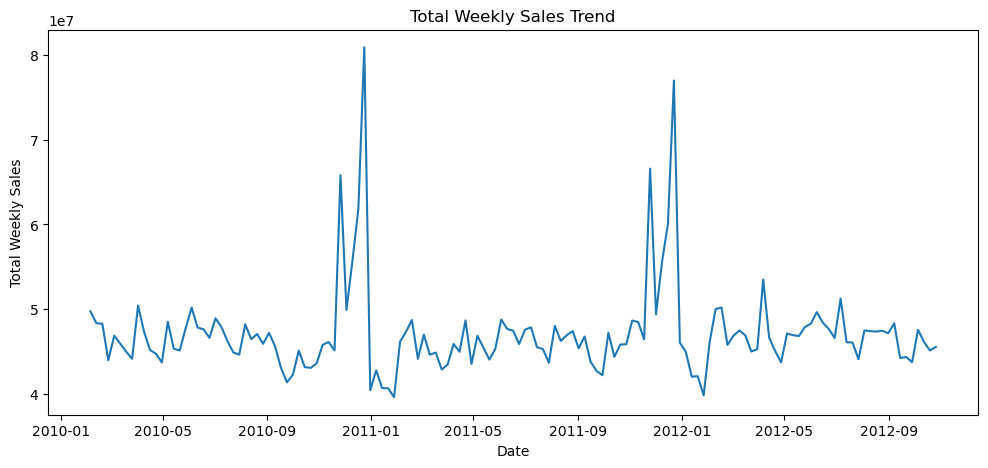

In [8]:
sales_trend = train_merged.groupby("Date")["Weekly_Sales"].sum().reset_index()

plt.figure(figsize=(12,5))
plt.plot(sales_trend["Date"], sales_trend["Weekly_Sales"])
plt.title("Total Weekly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.show()

#### Holiday Effect

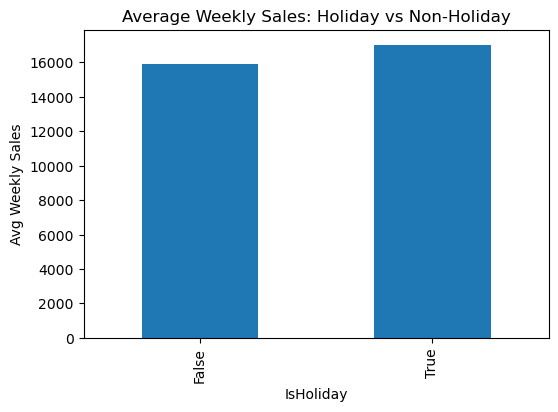

In [9]:
holiday_sales = train_merged.groupby("IsHoliday")["Weekly_Sales"].mean()

plt.figure(figsize=(6,4))
holiday_sales.plot(kind="bar")
plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.ylabel("Avg Weekly Sales")
plt.show()

#### Store Type Sales Comparison

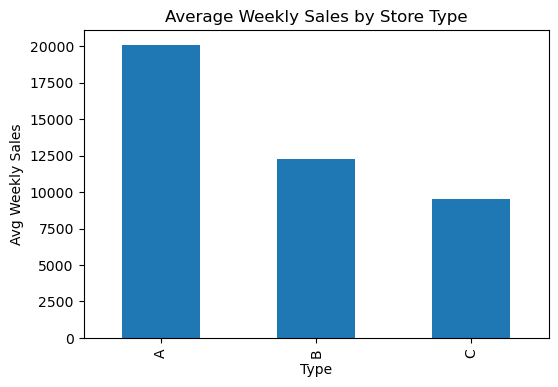

In [10]:
type_sales = train_merged.groupby("Type")["Weekly_Sales"].mean()

plt.figure(figsize=(6,4))
type_sales.plot(kind="bar")
plt.title("Average Weekly Sales by Store Type")
plt.ylabel("Avg Weekly Sales")
plt.show()

#### Feature Engineering

In [11]:
#Create Date Features

def create_date_features(df):
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
    df["Quarter"] = df["Date"].dt.quarter
    return df

train_merged = create_date_features(train_merged)
test_merged = create_date_features(test_merged)

In [12]:
## Create Lag & Rolling Features (Store + Dept)

In [13]:
train_merged = train_merged.sort_values(["Store", "Dept", "Date"])

for lag in [1, 2, 4, 8]:
    train_merged[f"lag_{lag}"] = train_merged.groupby(["Store", "Dept"])["Weekly_Sales"].shift(lag)

for window in [4, 8, 12]:
    train_merged[f"roll_mean_{window}"] = (
        train_merged.groupby(["Store", "Dept"])["Weekly_Sales"]
        .shift(1)
        .rolling(window)
        .mean()
    )

lag_cols = [col for col in train_merged.columns if "lag_" in col or "roll_mean" in col]
train_merged[lag_cols] = train_merged[lag_cols].fillna(0)

train_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Month,Week,Quarter,lag_1,lag_2,lag_4,lag_8,roll_mean_4,roll_mean_8,roll_mean_12
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,2,5,1,0.00,0.00,0.0,0.0,0.00,0.0,0.0
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,2,6,1,24924.50,0.00,0.0,0.0,0.00,0.0,0.0
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,2,7,1,46039.49,24924.50,0.0,0.0,0.00,0.0,0.0
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,2,8,1,41595.55,46039.49,0.0,0.0,0.00,0.0,0.0
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,3,9,1,19403.54,41595.55,24924.5,0.0,32990.77,0.0,0.0


# Train/Validation Split (Time-Based)

We split based on time to avoid leakage.

In [14]:
cutoff_date = "2012-01-01"

train_data = train_merged[train_merged["Date"] < cutoff_date]
val_data = train_merged[train_merged["Date"] >= cutoff_date]

print(train_data.shape, val_data.shape)

(294132, 27) (127438, 27)


## Evaluation Metrics

In [15]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / (y_true + 1e-9))) * 100

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("MAE:", mean_absolute_error(y_true, y_pred))
    print("RMSE:", rmse(y_true, y_pred))
    print("MAPE:", mape(y_true, y_pred))

## PART A: SARIMAX Forecasting (Aggregate Sales)

In [16]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarimax_df = train_merged.groupby("Date")["Weekly_Sales"].sum().reset_index()
sarimax_df = sarimax_df.set_index("Date")

sarimax_train = sarimax_df[sarimax_df.index < cutoff_date]
sarimax_val = sarimax_df[sarimax_df.index >= cutoff_date]

sarimax_model = SARIMAX(
    sarimax_train,
    order=(1,1,1),
    seasonal_order=(1,1,1,52)
)

sarimax_result = sarimax_model.fit(disp=False)

sarimax_forecast = sarimax_result.forecast(steps=len(sarimax_val))

evaluate_model(sarimax_val["Weekly_Sales"], sarimax_forecast, "SARIMAX")

C:\Users\User\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\User\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)



--- SARIMAX ---
MAE: 10570583.412906736
RMSE: 10893740.468239399
MAPE: 22.718831234790667


# Plot:

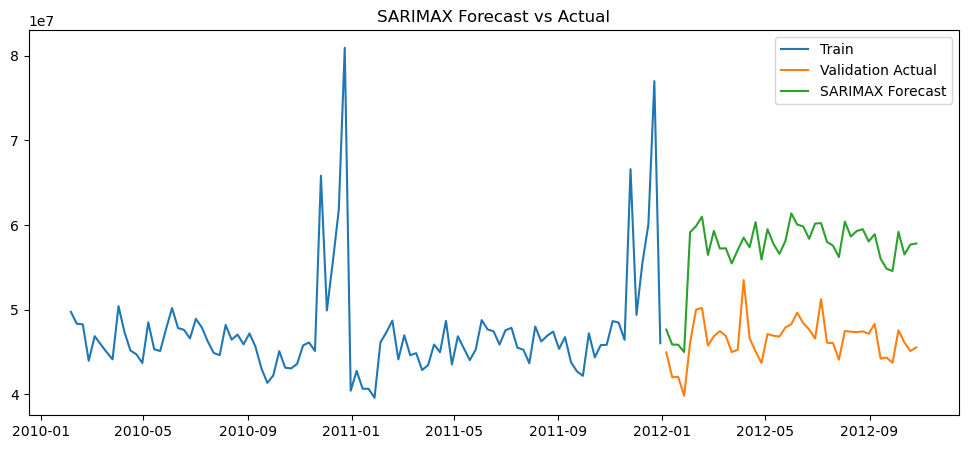

In [17]:
plt.figure(figsize=(12,5))
plt.plot(sarimax_train.index, sarimax_train["Weekly_Sales"], label="Train")
plt.plot(sarimax_val.index, sarimax_val["Weekly_Sales"], label="Validation Actual")
plt.plot(sarimax_val.index, sarimax_forecast, label="SARIMAX Forecast")
plt.title("SARIMAX Forecast vs Actual")
plt.legend()
plt.show()

## PART B: Prophet Forecasting

In [18]:
from prophet import Prophet

prophet_df = sarimax_df.reset_index()
prophet_df.columns = ["ds", "y"]

prophet_train = prophet_df[prophet_df["ds"] < cutoff_date]
prophet_val = prophet_df[prophet_df["ds"] >= cutoff_date]

prophet_model = Prophet(yearly_seasonality=True)
prophet_model.fit(prophet_train)

future = prophet_model.make_future_dataframe(periods=len(prophet_val), freq="W-FRI")
forecast = prophet_model.predict(future)

prophet_preds = forecast.iloc[-len(prophet_val):]["yhat"].values

evaluate_model(prophet_val["y"], prophet_preds, "Prophet")

10:50:43 - cmdstanpy - INFO - Chain [1] start processing
10:50:44 - cmdstanpy - INFO - Chain [1] done processing



--- Prophet ---
MAE: 1772869.9798945002
RMSE: 2399581.933441685
MAPE: 3.7913973834106196


#### Plot:

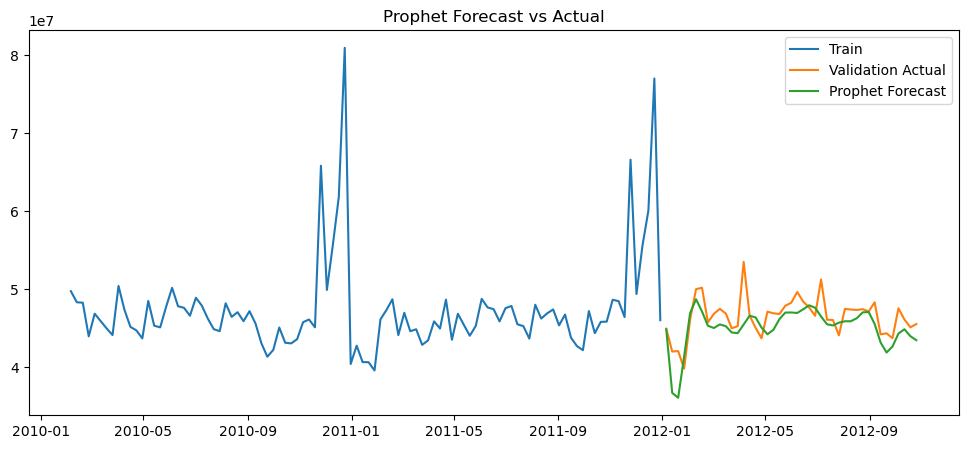

In [19]:
plt.figure(figsize=(12,5))
plt.plot(prophet_train["ds"], prophet_train["y"], label="Train")
plt.plot(prophet_val["ds"], prophet_val["y"], label="Validation Actual")
plt.plot(prophet_val["ds"], prophet_preds, label="Prophet Forecast")
plt.title("Prophet Forecast vs Actual")
plt.legend()
plt.show()

## PART C: XGBoost Forecasting (Store + Dept Level)

In [20]:
# Encode Store Type

ml_train = train_data.copy()
ml_val = val_data.copy()

le = LabelEncoder()
ml_train["Type"] = le.fit_transform(ml_train["Type"])
ml_val["Type"] = le.transform(ml_val["Type"])

In [21]:
# Select Features

target = "Weekly_Sales"

feature_cols = [
    "Store", "Dept", "IsHoliday", "Temperature", "Fuel_Price",
    "CPI", "Unemployment", "Size", "Type",
    "Year", "Month", "Week", "Quarter"
] + lag_cols

X_train = ml_train[feature_cols]
y_train = ml_train[target]

X_val = ml_val[feature_cols]
y_val = ml_val[target]


#### Baseline XGBoost Model

In [22]:
xgb_baseline = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_baseline.fit(X_train, y_train)

baseline_preds = xgb_baseline.predict(X_val)

evaluate_model(y_val, baseline_preds, "XGBoost Baseline")


--- XGBoost Baseline ---
MAE: 1422.8971504306703
RMSE: 2978.206686147436
MAPE: 3446890984.631566


#### TimeSeriesSplit Cross-Validation

In [23]:
# We apply TimeSeriesSplit to prevent future leakage.

tscv = TimeSeriesSplit(n_splits=5)

cv_rmse_scores = []

for train_index, test_index in tscv.split(X_train):
    X_tr, X_te = X_train.iloc[train_index], X_train.iloc[test_index]
    y_tr, y_te = y_train.iloc[train_index], y_train.iloc[test_index]
    
    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
    
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    
    cv_rmse_scores.append(rmse(y_te, preds))

print("TimeSeriesSplit RMSE Scores:", cv_rmse_scores)
print("Average CV RMSE:", np.mean(cv_rmse_scores))

TimeSeriesSplit RMSE Scores: [np.float64(7117.805936314132), np.float64(4958.484602471379), np.float64(4866.819550766194), np.float64(4274.193265387252), np.float64(3855.854492972469)]
Average CV RMSE: 5014.631569582286


#### Hyperparameter Tuning with RandomizedSearchCV

In [24]:
param_grid = {
    "n_estimators": [200, 400, 600, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [4, 6, 8, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0]
}

xgb_model = XGBRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV RMSE:", -random_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Parameters: {'subsample': 0.8, 'n_estimators': 800, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
Best CV RMSE: 4691.984706554363


#### Train Best Model + Evaluate on Validation Set

In [25]:
best_xgb = random_search.best_estimator_

best_xgb.fit(X_train, y_train)

tuned_preds = best_xgb.predict(X_val)

evaluate_model(y_val, tuned_preds, "XGBoost Tuned")


--- XGBoost Tuned ---
MAE: 1483.1277753043566
RMSE: 3116.077029397193
MAPE: 4627185687.046373


#### Error Analysis by Store Type

In [26]:
ml_val_copy = ml_val.copy()
ml_val_copy["Predicted_Sales"] = tuned_preds
ml_val_copy["Absolute_Error"] = np.abs(ml_val_copy["Weekly_Sales"] - ml_val_copy["Predicted_Sales"])

error_by_type = ml_val_copy.groupby("Type")["Absolute_Error"].mean().reset_index()
error_by_type

,Type,Absolute_Error
0,0,1785.459439
1,1,1280.257136
2,2,751.959942


#### Plot:

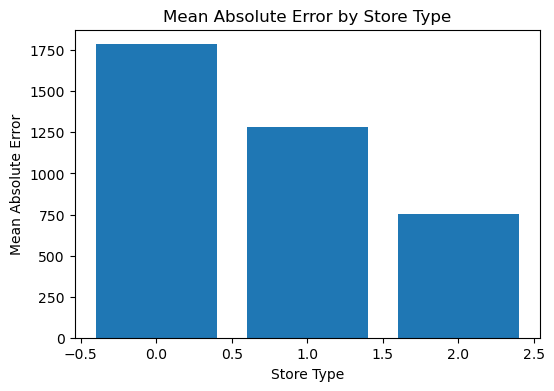

In [27]:
plt.figure(figsize=(6,4))
plt.bar(error_by_type["Type"], error_by_type["Absolute_Error"])
plt.title("Mean Absolute Error by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Mean Absolute Error")
plt.show()

#### Error Analysis by Department

In [28]:
error_by_dept = ml_val_copy.groupby("Dept")["Absolute_Error"].mean().reset_index()
error_by_dept = error_by_dept.sort_values("Absolute_Error", ascending=False)

error_by_dept.head(10)

,Dept,Absolute_Error
60,72,5677.707219
36,38,5576.122051
73,92,4862.401116
76,95,3738.188848
57,65,3698.479306
0,1,3105.418638
6,7,2887.641609
14,16,2862.821742
4,5,2752.618692
8,9,2720.404811


Plot top 15 worst departments:

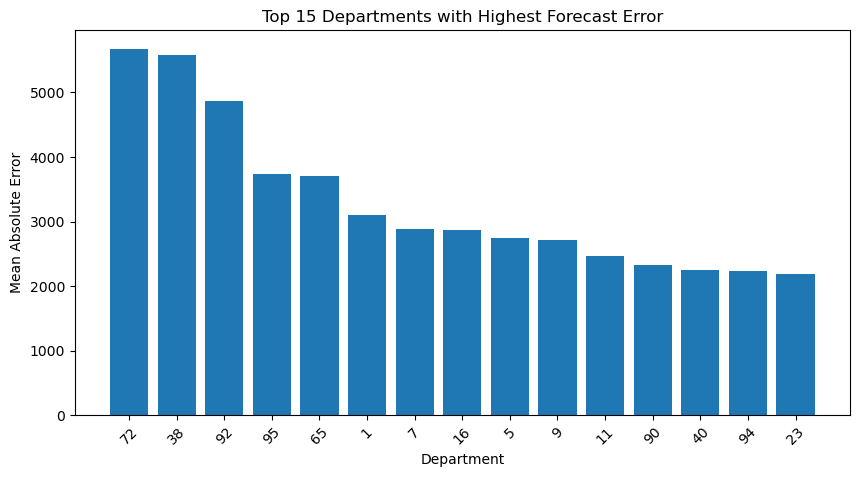

In [29]:
top_depts = error_by_dept.head(15)

plt.figure(figsize=(10,5))
plt.bar(top_depts["Dept"].astype(str), top_depts["Absolute_Error"])
plt.title("Top 15 Departments with Highest Forecast Error")
plt.xlabel("Department")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=45)
plt.show()

### Interactive Plotly Dashboard

#### Sales Trend Dashboard

In [30]:
fig = px.line(
    sales_trend,
    x="Date",
    y="Weekly_Sales",
    title="Total Weekly Sales Trend (Interactive)"
)

fig.show()

#### Holiday Sales Dashboard

In [31]:
holiday_df = train_merged.groupby(["Date", "IsHoliday"])["Weekly_Sales"].sum().reset_index()

fig = px.line(
    holiday_df,
    x="Date",
    y="Weekly_Sales",
    color="IsHoliday",
    title="Holiday vs Non-Holiday Weekly Sales Trend"
)

fig.show()

#### Store Type Sales Dashboard

In [32]:
type_df = train_merged.groupby(["Date", "Type"])["Weekly_Sales"].sum().reset_index()

fig = px.line(
    type_df,
    x="Date",
    y="Weekly_Sales",
    color="Type",
    title="Weekly Sales Trend by Store Type"
)

fig.show()

#### Final Model Training on Full Dataset + Predict Test

In [33]:
# Create Lag/Roll Features for Full Data

full_data = pd.concat([train_merged, test_merged], axis=0, sort=False)
full_data = full_data.sort_values(["Store", "Dept", "Date"])

for lag in [1, 2, 4, 8]:
    full_data[f"lag_{lag}"] = full_data.groupby(["Store", "Dept"])["Weekly_Sales"].shift(lag)

for window in [4, 8, 12]:
    full_data[f"roll_mean_{window}"] = (
        full_data.groupby(["Store", "Dept"])["Weekly_Sales"]
        .shift(1)
        .rolling(window)
        .mean()
    )

full_data[lag_cols] = full_data[lag_cols].fillna(0)

Split back:

In [35]:
final_train = full_data[full_data["Weekly_Sales"].notnull()]
final_test = full_data[full_data["Weekly_Sales"].isnull()]

Encode store type:

In [ ]:
final_train["Type"] = le.fit_transform(final_train["Type"])
final_test["Type"] = le.transform(final_test["Type"])

Train final model:

In [37]:
X_final_train = final_train[feature_cols]
y_final_train = final_train["Weekly_Sales"]

X_final_test = final_test[feature_cols]

best_xgb.fit(X_final_train, y_final_train)

test_preds = best_xgb.predict(X_final_test)

ValueError: DataFrame.dtypes for data must be int, float, bool or category. When categorical type is supplied, the experimental DMatrix parameter`enable_categorical` must be set to `True`.  Invalid columns:Type: object

# 20. Create Submission File

In [ ]:
submission = pd.DataFrame({
    "Id": test["Store"].astype(str) + "_" + test["Dept"].astype(str) + "_" + test["Date"].astype(str),
    "Weekly_Sales": test_preds
})

submission.to_csv("submission.csv", index=False)
submission.head()

# 21. Model Comparison Summary Table

In [ ]:
results = pd.DataFrame({
    "Model": ["SARIMAX", "Prophet", "XGBoost Tuned"],
    "RMSE": [
        rmse(sarimax_val["Weekly_Sales"], sarimax_forecast),
        rmse(prophet_val["y"], prophet_preds),
        rmse(y_val, tuned_preds)
    ],
    "MAE": [
        mean_absolute_error(sarimax_val["Weekly_Sales"], sarimax_forecast),
        mean_absolute_error(prophet_val["y"], prophet_preds),
        mean_absolute_error(y_val, tuned_preds)
    ],
    "MAPE": [
        mape(sarimax_val["Weekly_Sales"], sarimax_forecast),
        mape(prophet_val["y"], prophet_preds),
        mape(y_val, tuned_preds)
    ]
})

results.sort_values("RMSE")

# Conclusion 

### Key Findings

* Sales show strong seasonal peaks around holiday periods.
* Store size and promotional markdowns significantly impact weekly sales.
* XGBoost with lag and rolling features outperformed classical forecasting methods.

### Recommendation

XGBoost is the most effective model for store-department level forecasting due to its ability to model complex nonlinear patterns and incorporate external regressors.